In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
data = pd.read_csv("data.csv")

x_train = data[['feature1', 'feature2']].values
y_train = data['label'].values

m, n = x_train.shape

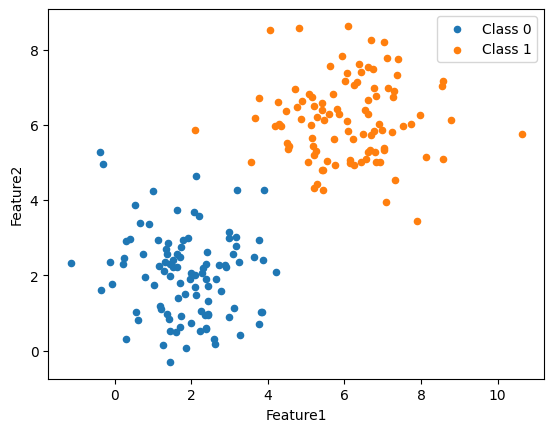

In [5]:
plt.scatter(x_train[y_train == 0, 0], x_train[y_train == 0, 1], color='tab:blue', label='Class 0', s=20)
plt.scatter(x_train[y_train == 1, 0], x_train[y_train ==1, 1], color='tab:orange', label='Class 1', s=20)
plt.xlabel('Feature1')
plt.ylabel('Feature2')
plt.legend()
plt.show()


### -------------------------------------------

# Sigmoid Function

In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

### -------------------------------------------

# Cost Function

In [7]:
def cost_function(x, y, w, b):
    cost_sum = 0

    for i in range(m):
        z = np.dot(w, x[i]) + b
        g = sigmoid(z)

        cost_sum += -y[i] * np.log(g) - (1 - y[i]) * np.log(1-g)

    return (1/m) * cost_sum

### -------------------------------------------

# Gradient Function 

In [8]:
def gradient_function(x, y, w, b):
    grad_w = np.zeros(n)
    grad_b = 0

    for i in range(m):
        z = np.dot(w, x[i]) + b
        g = sigmoid(z)

        grad_b += (g-y[i])
        for j in range(n):
            grad_w[j] += (g-y[i]) * x[i, j]

    grad_b = (1/m) * grad_b
    grad_w = (1/m) * grad_w

    return grad_b, grad_w

### -------------------------------------------

# Gradient Descent

In [9]:
def gradient_descent(x, y, alpha, iterations):
    w = np.zeros(n)
    b = 0

    for i in range(iterations):
        grad_b, grad_w = gradient_function(x, y, w, b)

        w = w - alpha * grad_w
        b = b - alpha * grad_b

        if 1 % 1000 == 0:
            print(f"Iteration {i}: Cost {cost_function(x, y, w, b)}")

    return w, b

### -------------------------------------------

In [10]:
def predict(x, w, b):
    preds = np.zeros(m)

    for i in range(m):
        z = np.dot(w, x[i]) + b
        g = sigmoid(z)

        preds [i] = 1 if g >= 0.5 else 0

    return preds

In [12]:
learning_rate = 0.01
iterations = 10000

final_w, final_b = gradient_descent(x_train, y_train, learning_rate, iterations)

predictions = predict(x_train, final_w, final_b)
accuracy = np.mean(predictions == y_train) * 100
print(f"training accuracy: {accuracy:.2f}%")

training accuracy: 99.00%


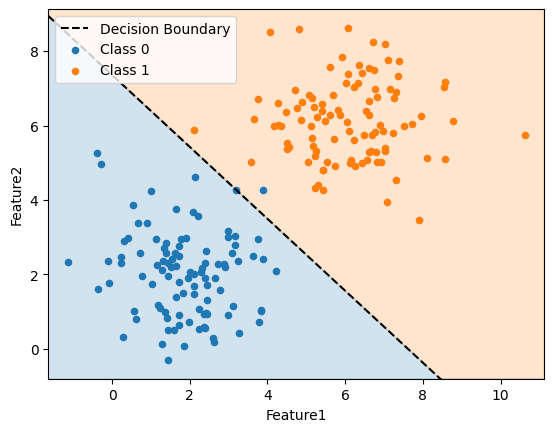

In [13]:
m = -final_w[0] / final_w[1]
c = -final_b / final_w[1]

xmin, xmax = x_train[:, 0].min() - 0.5, x_train[:, 0].max() + 0.5
ymin, ymax = x_train[:, 1].min() - 0.5, x_train[:, 1].max() + 0.5
xd = np.array([xmin, xmax])
yd = m * xd + c

plt.plot(xd, yd, 'k', ls='--', label='Decision Boundary')
plt.fill_between(xd, yd, ymin, color='tab:blue', alpha=0.2)
plt.fill_between(xd, yd, ymax, color='tab:orange', alpha=0.2)

plt.scatter(x_train[y_train == 0,0], x_train[y_train == 0, 1], color='tab:blue', label='Class 0', s=20)
plt.scatter(x_train[y_train == 1,0], x_train[y_train == 1, 1], color='tab:orange', label='Class 1', s=20)
plt.legend()
plt.xlabel('Feature1')
plt.ylabel('Feature2')
plt.xlim(xmin, xmax)
plt.ylim(ymin, ymax)
plt.show()